# Swing Path Tilt — MLB Assessment
Explores `swing_path_tilt` as a standalone metric and in combination with
`attack_direction` to predict batted ball outcomes.

**Sections**
1. Imports & config
2. Load Statcast data
3. Distribution analysis
4. Reliability (Cronbach's α)
5. Stickiness (2024→2025 YoY Spearman ρ)
6. Outcome correlations
7. Joint distribution with attack direction
8. Regression analysis (tilt, direction, interactions)


## 1. Imports & Config

In [9]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy.stats import spearmanr, pearsonr
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:.3f}".format)

MIN_BBE  = 25
N_ITEMS  =  5
N_SPLITS = 200

print("Imports OK")


Imports OK


## 2. Load Statcast Data

In [10]:
raw_2024 = pd.read_parquet(Path("statcast_2024.parquet"))
raw_2025 = pd.read_parquet(Path("statcast_2025.parquet"))

def filter_contact(df):
    mask = (
        df["swing_path_tilt"].notna() &
        df["attack_direction"].notna() &
        df["launch_speed"].notna() &
        df["launch_angle"].notna() &
        df["stand"].notna()
    )
    return df[mask].copy().reset_index(drop=True)

ip_2024 = filter_contact(raw_2024)
ip_2025 = filter_contact(raw_2025)
ip_all  = pd.concat([ip_2024, ip_2025], ignore_index=True)

print(f"2024: {len(ip_2024):,} events  ({ip_2024['batter'].nunique()} batters)")
print(f"2025: {len(ip_2025):,} events  ({ip_2025['batter'].nunique()} batters)")
print(f"Combined: {len(ip_all):,}")

# ── Derived outcome columns
for df in [ip_2024, ip_2025, ip_all]:
    df["sweet_spot"]  = df["launch_angle"].between(8, 32).astype(int)
    df["barrel_adj"]  = (
        (df["launch_speed"] >= 98) & df["launch_angle"].between(26, 30)
    ).astype(int)
    df["ground_ball"] = (df["launch_angle"] < 10).astype(int)
    df["fly_ball"]    = (df["launch_angle"] > 25).astype(int)
    df["hc_x_norm"]   = np.where(df["stand"] == "R",
                                  df["hc_x"] - 125, 125 - df["hc_x"])
    df["pull_flag"]   = (df["hc_x_norm"] > 5).astype(int)
    df["pull_air"]    = (
        (df["hc_x_norm"] > 5) & (df["launch_angle"] > 10)
    ).astype(int)

print("Outcome columns added.")


2024: 220,935 events  (650 batters)
2025: 228,609 events  (771 batters)
Combined: 449,544
Outcome columns added.


## 3. Distribution Analysis

swing_path_tilt:
count   449544.000
mean        32.070
std          6.930
min          0.670
25%         27.510
50%         32.090
75%         36.640
max         89.920
Name: swing_path_tilt, dtype: Float64


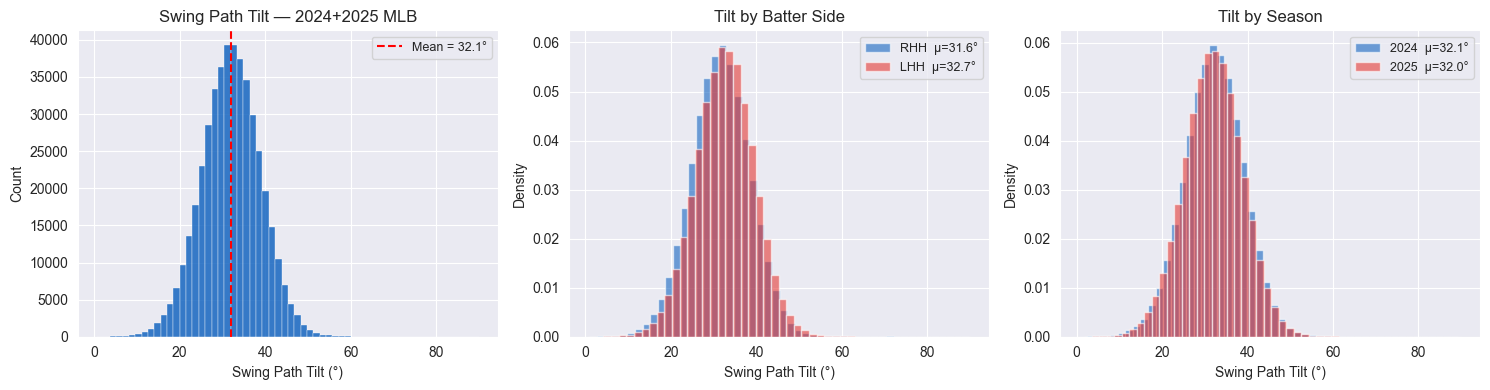

RHH — mean=31.61°  std=6.94°  range=[0.9°, 89.9°]
LHH — mean=32.66°  std=6.88°  range=[0.7°, 89.7°]


In [11]:
tilt = ip_all["swing_path_tilt"]
print("swing_path_tilt:")
print(tilt.describe().round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(tilt, bins=60, color="#1565C0", alpha=0.85,
             edgecolor="white", linewidth=0.3)
axes[0].axvline(tilt.mean(), color="red", linewidth=1.5, linestyle="--",
                label=f"Mean = {tilt.mean():.1f}°")
axes[0].set_xlabel("Swing Path Tilt (°)")
axes[0].set_ylabel("Count")
axes[0].set_title("Swing Path Tilt — 2024+2025 MLB")
axes[0].legend(fontsize=9)

for side, color, label in [("R", "#1565C0", "RHH"), ("L", "#E53935", "LHH")]:
    sub = ip_all[ip_all["stand"] == side]["swing_path_tilt"]
    axes[1].hist(sub, bins=50, alpha=0.6, color=color,
                 label=f"{label}  μ={sub.mean():.1f}°", density=True)
axes[1].set_xlabel("Swing Path Tilt (°)")
axes[1].set_ylabel("Density")
axes[1].set_title("Tilt by Batter Side")
axes[1].legend(fontsize=9)

for year, df_yr, color in [(2024, ip_2024, "#1565C0"), (2025, ip_2025, "#E53935")]:
    sub = df_yr["swing_path_tilt"]
    axes[2].hist(sub, bins=50, alpha=0.6, color=color,
                 label=f"{year}  μ={sub.mean():.1f}°", density=True)
axes[2].set_xlabel("Swing Path Tilt (°)")
axes[2].set_ylabel("Density")
axes[2].set_title("Tilt by Season")
axes[2].legend(fontsize=9)

plt.tight_layout()
plt.show()

for side in ["R", "L"]:
    sub = ip_all[ip_all["stand"] == side]["swing_path_tilt"]
    print(f"{side}HH — mean={sub.mean():.2f}°  std={sub.std():.2f}°  "
          f"range=[{sub.min():.1f}°, {sub.max():.1f}°]")


## 4. Reliability (Cronbach's α)

In [12]:
def cronbach_alpha(items_df):
    k         = items_df.shape[1]
    item_var  = items_df.var(axis=0, ddof=1).sum()
    total_var = items_df.sum(axis=1).var(ddof=1)
    return np.nan if total_var == 0 else (k / (k - 1)) * (1 - item_var / total_var)

def reliability_at_threshold(df, col, thresh):
    eligible = [
        bid for bid, grp in df.groupby("batter")
        if len(grp) >= thresh * N_ITEMS
    ]
    if len(eligible) < 20:
        return None
    sub    = df[df["batter"].isin(eligible)]
    alphas = []
    for _ in range(N_SPLITS):
        rows = []
        for bid, grp in sub.groupby("batter"):
            shuffled    = grp.sample(frac=1)
            chunk_means = [shuffled.iloc[i::N_ITEMS][col].mean()
                           for i in range(N_ITEMS)]
            rows.append(chunk_means)
        items = pd.DataFrame(rows).dropna()
        if len(items) < 10:
            continue
        alphas.append(cronbach_alpha(items))
    return {
        "thresh":     thresh,
        "n_batters":  len(eligible),
        "alpha_mean": float(np.mean(alphas)),
        "alpha_std":  float(np.std(alphas)),
    } if alphas else None

thresholds = list(range(10, 50, 10))

print("Reliability — swing_path_tilt …")
rel_tilt = pd.DataFrame([
    r for t in thresholds
    if (r := reliability_at_threshold(ip_2024, "swing_path_tilt", t))
])

print("Reliability — attack_direction …")
rel_dir = pd.DataFrame([
    r for t in thresholds
    if (r := reliability_at_threshold(ip_2024, "attack_direction", t))
])

print("Done.")


Reliability — swing_path_tilt …


KeyboardInterrupt: 

In [ ]:
fig, ax1 = plt.subplots(figsize=(10, 5))
ax2 = ax1.twinx()

for rel, color, label in [
    (rel_tilt, "#1565C0", "Swing Path Tilt"),
    (rel_dir,  "#E53935", "Attack Direction"),
]:
    ax1.plot(rel["thresh"], rel["alpha_mean"], color=color, linewidth=2, label=label)
    ax1.fill_between(rel["thresh"],
                     rel["alpha_mean"] - rel["alpha_std"],
                     rel["alpha_mean"] + rel["alpha_std"],
                     alpha=0.1, color=color)

ax1.axhline(0.70, color="gray",   linewidth=1, linestyle="--", label="α = 0.70")
ax1.axhline(0.80, color="orange", linewidth=1, linestyle="--", label="α = 0.80")
ax1.set_xlabel("Minimum BBE threshold")
ax1.set_ylabel("Cronbach's α")
ax1.set_title("Reliability — Tilt vs. Direction")
ax1.legend(fontsize=9)
ax1.set_ylim(0, 1)

ax2.bar(rel_tilt["thresh"], rel_tilt["n_batters"], alpha=0.1, color="gray", width=4)
ax2.set_ylabel("N batters (tilt)", color="gray")
ax2.tick_params(axis="y", labelcolor="gray")

plt.tight_layout()
plt.show()

for metric, rel in [("Tilt", rel_tilt), ("Direction", rel_dir)]:
    for target, thresh in [(0.70, "α=0.70"), (0.80, "α=0.80")]:
        cross = rel[rel["alpha_mean"] >= target]
        if not cross.empty:
            print(f"{metric:10s}  {thresh} first at BBE = {cross.iloc[0]['thresh']}")


## 5. Stickiness (2024→2025 YoY Spearman ρ)

In [16]:
def batter_season_means(df, col, min_bbe):
    return (
        df.groupby("batter")[col]
        .agg(n="count", mean="mean")
        .query(f"n >= {min_bbe}")["mean"]
    )

stick_results = []
print(f"{'min_bbe':>8}  {'n_paired':>10}  {'tilt_rho':>10}  {'dir_rho':>10}")
for min_bbe in range(10, 155, 5):
    t24 = batter_season_means(ip_2024, "swing_path_tilt",  min_bbe)
    t25 = batter_season_means(ip_2025, "swing_path_tilt",  min_bbe)
    d24 = batter_season_means(ip_2024, "attack_direction", min_bbe)
    d25 = batter_season_means(ip_2025, "attack_direction", min_bbe)

    paired_t = t24.rename("y2024").to_frame().join(t25.rename("y2025"), how="inner")
    paired_d = d24.rename("y2024").to_frame().join(d25.rename("y2025"), how="inner")

    if len(paired_t) < 20:
        continue

    rho_t, _ = spearmanr(paired_t["y2024"], paired_t["y2025"])
    rho_d    = spearmanr(paired_d["y2024"], paired_d["y2025"])[0] if len(paired_d) >= 20 else np.nan

    stick_results.append({"min_bbe": min_bbe, "n_paired": len(paired_t),
                           "tilt_rho": rho_t, "dir_rho": rho_d})
    print(f"{min_bbe:>8}  {len(paired_t):>10}  {rho_t:>10.4f}  {rho_d:>10.4f}")

stick = pd.DataFrame(stick_results)


 min_bbe    n_paired    tilt_rho     dir_rho
      10         511      0.8849      0.7408
      15         498      0.8900      0.7520
      20         483      0.8914      0.7674
      25         467      0.8930      0.7769
      30         457      0.8956      0.7897
      35         452      0.8967      0.7916
      40         440      0.9037      0.7933
      45         435      0.9052      0.7994
      50         426      0.9048      0.7977
      55         420      0.9035      0.7991
      60         411      0.9015      0.8026
      65         407      0.9064      0.8078
      70         401      0.9058      0.8109
      75         396      0.9064      0.8091
      80         393      0.9048      0.8059
      85         388      0.9052      0.8028
      90         385      0.9065      0.8037
      95         378      0.9050      0.8073
     100         374      0.9051      0.8060
     105         371      0.9043      0.8111
     110         367      0.9055      0.8144
     115  

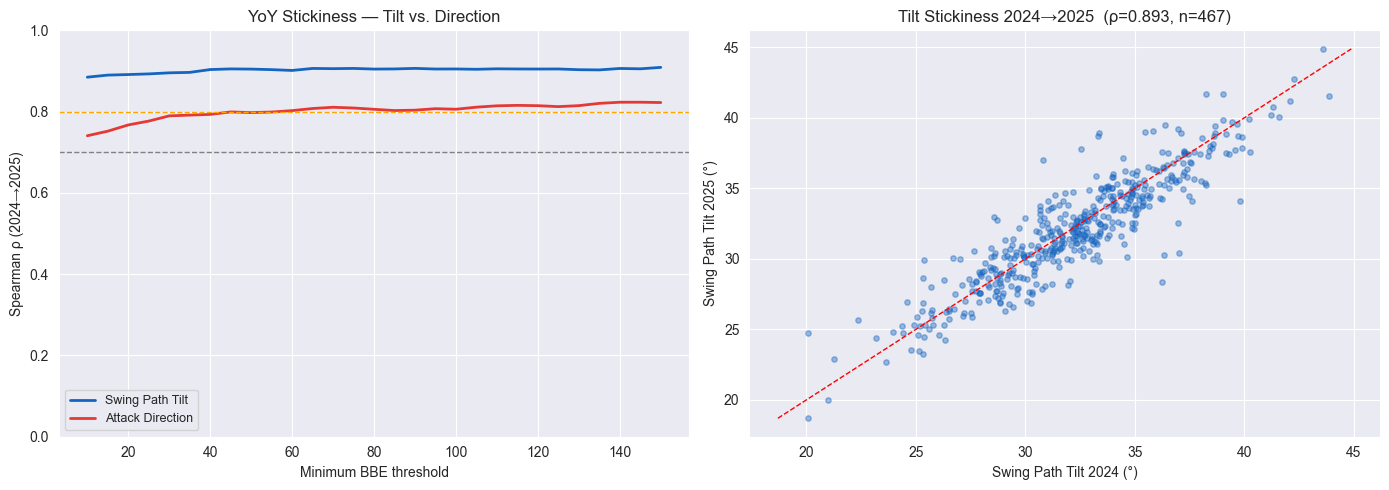

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(stick["min_bbe"], stick["tilt_rho"],
             color="#1565C0", linewidth=2, label="Swing Path Tilt")
axes[0].plot(stick["min_bbe"], stick["dir_rho"],
             color="#E53935", linewidth=2, label="Attack Direction")
axes[0].axhline(0.70, color="gray",   linewidth=1, linestyle="--")
axes[0].axhline(0.80, color="orange", linewidth=1, linestyle="--")
axes[0].set_xlabel("Minimum BBE threshold")
axes[0].set_ylabel("Spearman ρ (2024→2025)")
axes[0].set_title("YoY Stickiness — Tilt vs. Direction")
axes[0].legend(fontsize=9)
axes[0].set_ylim(0, 1)

t24 = batter_season_means(ip_2024, "swing_path_tilt", MIN_BBE)
t25 = batter_season_means(ip_2025, "swing_path_tilt", MIN_BBE)
paired = t24.rename("y2024").to_frame().join(t25.rename("y2025"), how="inner")
rho_plot, _ = spearmanr(paired["y2024"], paired["y2025"])

axes[1].scatter(paired["y2024"], paired["y2025"], alpha=0.4, s=15, color="#1565C0")
lims = [paired.min().min(), paired.max().max()]
axes[1].plot(lims, lims, "r--", linewidth=1)
axes[1].set_xlabel("Swing Path Tilt 2024 (°)")
axes[1].set_ylabel("Swing Path Tilt 2025 (°)")
axes[1].set_title(f"Tilt Stickiness 2024→2025  (ρ={rho_plot:.3f}, n={len(paired)})")

plt.tight_layout()
plt.show()


## 6. Outcome Correlations (Batter Level)

In [18]:
batter_agg = (
    ip_all.groupby("batter")
    .agg(
        n              = ("swing_path_tilt", "count"),
        mean_tilt      = ("swing_path_tilt", "mean"),
        mean_direction = ("attack_direction","mean"),
        sweet_spot_pct = ("sweet_spot",      "mean"),
        barrel_pct     = ("barrel_adj",      "mean"),
        gb_pct         = ("ground_ball",     "mean"),
        fb_pct         = ("fly_ball",        "mean"),
        pull_pct       = ("pull_flag",       "mean"),
        pull_air_pct   = ("pull_air",        "mean"),
        mean_la        = ("launch_angle",    "mean"),
        mean_ev        = ("launch_speed",    "mean"),
        stand          = ("stand",           "first"),
    )
    .query(f"n >= {MIN_BBE}")
    .reset_index()
)

print(f"Qualified batters: {len(batter_agg)}")

outcome_cols = {
    "Sweet Spot%":  "sweet_spot_pct",
    "Barrel%":      "barrel_pct",
    "Ground Ball%": "gb_pct",
    "Fly Ball%":    "fb_pct",
    "Pull%":        "pull_pct",
    "PullAir%":     "pull_air_pct",
    "Mean LA":      "mean_la",
    "Mean EV":      "mean_ev",
}

print(f"\n{'Outcome':<15} {'Tilt r':>8} {'Tilt ρ':>8} {'Dir r':>8} {'Dir ρ':>8}")
print("-" * 50)
for label, col in outcome_cols.items():
    sub  = batter_agg[["mean_tilt", "mean_direction", col]].dropna()
    r_t, _ = pearsonr(sub["mean_tilt"],      sub[col])
    s_t, _ = spearmanr(sub["mean_tilt"],     sub[col])
    r_d, _ = pearsonr(sub["mean_direction"], sub[col])
    s_d, _ = spearmanr(sub["mean_direction"],sub[col])
    print(f"{label:<15} {r_t:>8.4f} {s_t:>8.4f} {r_d:>8.4f} {s_d:>8.4f}")


Qualified batters: 713

Outcome           Tilt r   Tilt ρ    Dir r    Dir ρ
--------------------------------------------------
Sweet Spot%       0.3279   0.3542   0.2155   0.2310
Barrel%           0.0177   0.0266  -0.1102  -0.1224
Ground Ball%     -0.1301  -0.1240   0.2123   0.1975
Fly Ball%        -0.0194  -0.0261  -0.3099  -0.3057
Pull%            -0.0262  -0.0258   0.4295   0.4182
PullAir%          0.1035   0.0937   0.1300   0.1463
Mean LA           0.0168   0.0154  -0.4013  -0.4021
Mean EV          -0.1070  -0.1067  -0.0208  -0.0252


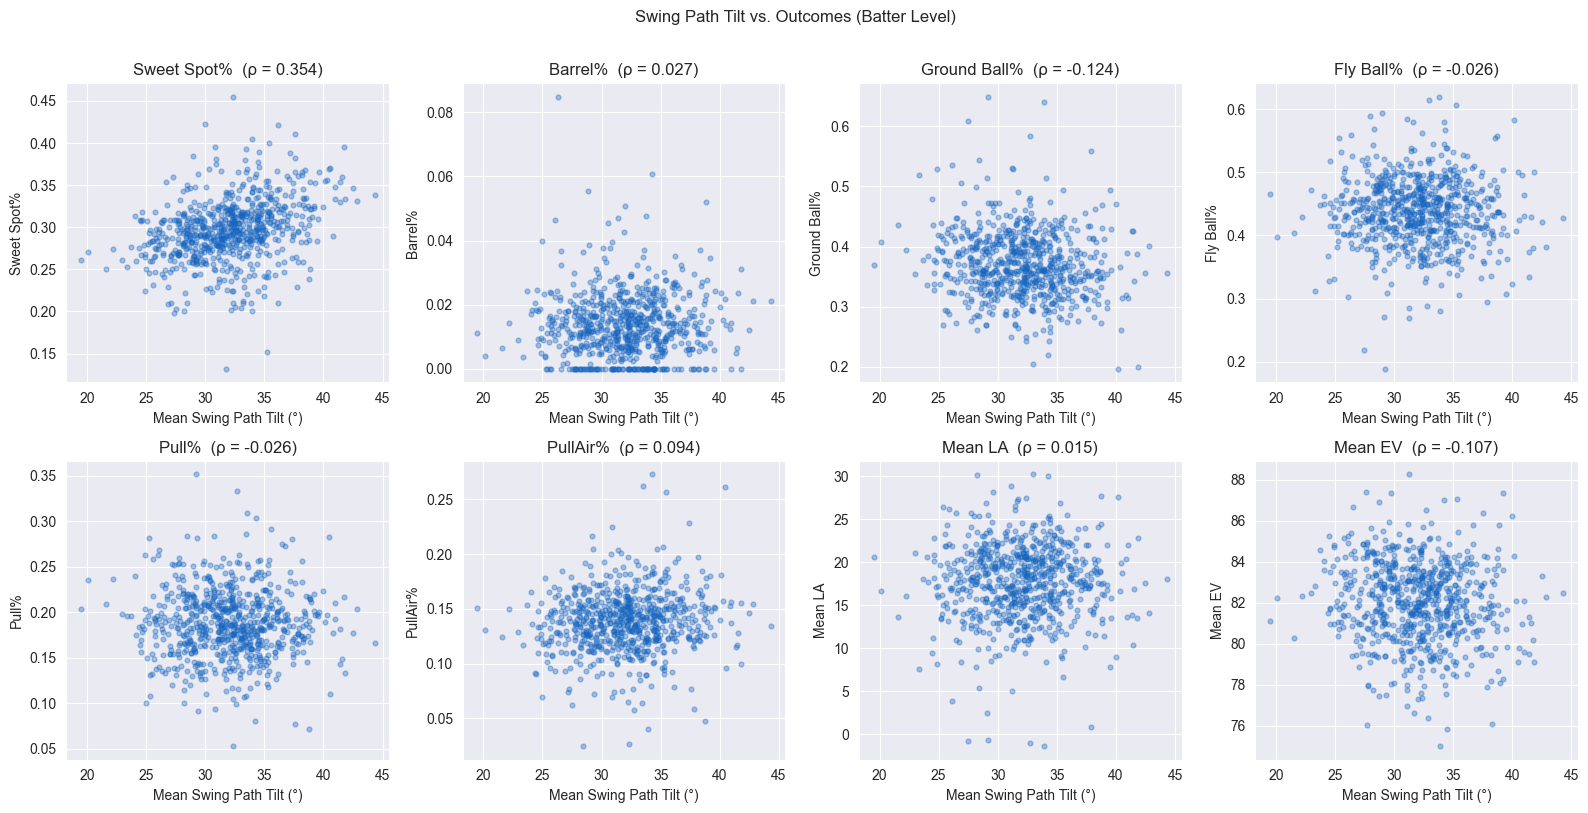

In [20]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for ax, (label, col) in zip(axes, outcome_cols.items()):
    sub  = batter_agg[["mean_tilt", col]].dropna()
    r_s, _ = spearmanr(sub["mean_tilt"], sub[col])
    ax.scatter(sub["mean_tilt"], sub[col], alpha=0.35, s=12, color="#1565C0")
    ax.set_xlabel("Mean Swing Path Tilt (°)")
    ax.set_ylabel(label)
    ax.set_title(f"{label}  (ρ = {r_s:.3f})")

plt.suptitle("Swing Path Tilt vs. Outcomes (Batter Level)", y=1.01, fontsize=12)
plt.tight_layout()
plt.show()


## 7. Joint Distribution — Tilt × Attack Direction

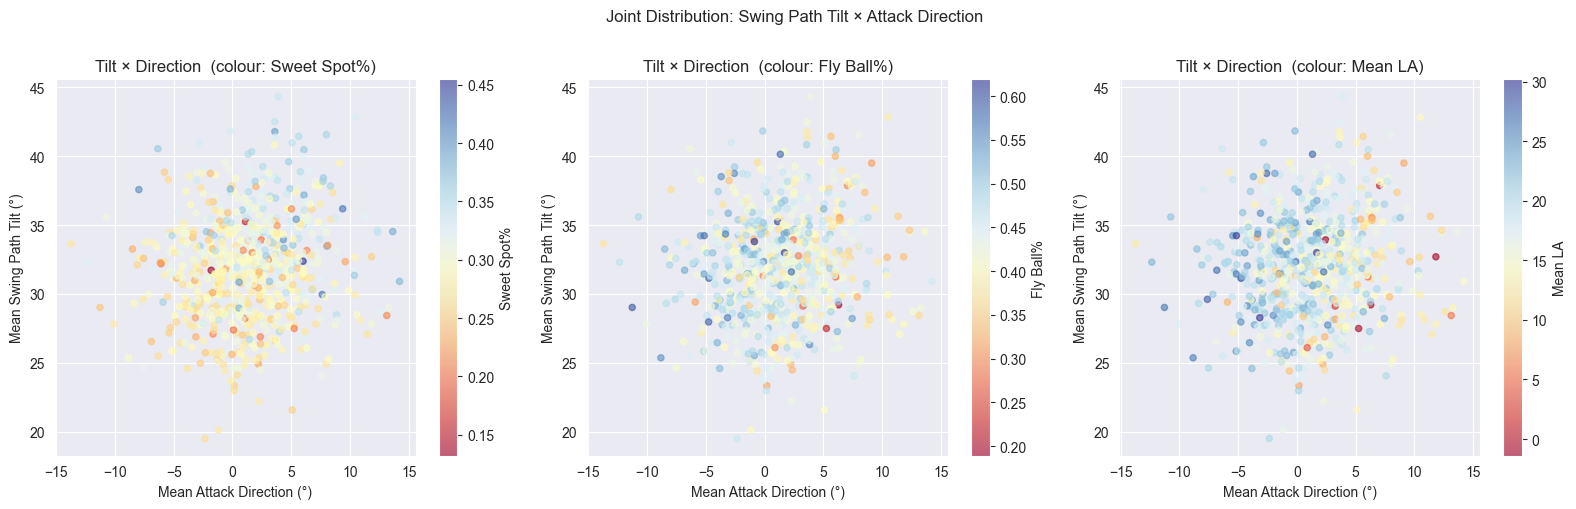

Tilt × Direction:  Pearson r=0.1025  Spearman ρ=0.1074


In [21]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (col, label, cmap) in zip(axes, [
    ("sweet_spot_pct", "Sweet Spot%", "RdYlBu"),
    ("fb_pct",         "Fly Ball%",   "RdYlBu"),
    ("mean_la",        "Mean LA",     "RdYlBu"),
]):
    sub = batter_agg[["mean_direction", "mean_tilt", col]].dropna()
    sc  = ax.scatter(sub["mean_direction"], sub["mean_tilt"],
                     c=sub[col], cmap=cmap, alpha=0.6, s=20)
    plt.colorbar(sc, ax=ax, label=label)
    ax.set_xlabel("Mean Attack Direction (°)")
    ax.set_ylabel("Mean Swing Path Tilt (°)")
    ax.set_title(f"Tilt × Direction  (colour: {label})")

plt.suptitle("Joint Distribution: Swing Path Tilt × Attack Direction",
             y=1.01, fontsize=12)
plt.tight_layout()
plt.show()

r_p, _ = pearsonr(batter_agg["mean_tilt"], batter_agg["mean_direction"])
r_s, _ = spearmanr(batter_agg["mean_tilt"], batter_agg["mean_direction"])
print(f"Tilt × Direction:  Pearson r={r_p:.4f}  Spearman ρ={r_s:.4f}")


## 8. Regression Analysis
Ridge regression predicting each outcome from:
- Tilt (T), Direction (D)
- Interaction: T×D
- Quadratic terms: T², D²

Reports standardised coefficients and 5-fold cross-validated R².


In [22]:
def run_regression(outcome_col):
    sub = batter_agg[["mean_tilt", "mean_direction", outcome_col]].dropna()
    T   = sub["mean_tilt"].values
    D   = sub["mean_direction"].values
    y   = sub[outcome_col].values

    X = np.column_stack([T, D, T*D, T**2, D**2])
    feat_names = ["Tilt", "Direction", "Tilt×Dir", "Tilt²", "Dir²"]

    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge",  RidgeCV(alphas=[0.01, 0.1, 1, 10, 100], cv=5)),
    ])
    pipe.fit(X, y)
    cv_r2 = cross_val_score(pipe, X, y, cv=5, scoring="r2").mean()

    return {
        "cv_r2": round(cv_r2, 4),
        "alpha": round(pipe.named_steps["ridge"].alpha_, 3),
        **dict(zip(feat_names, [round(c, 4) for c in pipe.named_steps["ridge"].coef_])),
    }

rows = []
for label, col in outcome_cols.items():
    r = run_regression(col)
    r["outcome"] = label
    rows.append(r)

reg_df = pd.DataFrame(rows).set_index("outcome")
print("Ridge Regression — Standardised Coefficients + 5-fold CV R²")
print(reg_df.to_string())


Ridge Regression — Standardised Coefficients + 5-fold CV R²
              cv_r2   alpha   Tilt  Direction  Tilt×Dir  Tilt²   Dir²
outcome                                                              
Sweet Spot%   0.130   1.000 -0.006     -0.004     0.011  0.017  0.001
Barrel%      -0.004 100.000  0.000     -0.001    -0.000  0.000 -0.000
Ground Ball%  0.043 100.000 -0.004      0.006     0.005 -0.004  0.002
Fly Ball%     0.069 100.000  0.001     -0.007    -0.007 -0.000 -0.002
Pull%         0.164  10.000 -0.002      0.016    -0.000 -0.001  0.000
PullAir%      0.009 100.000  0.001      0.002     0.002  0.001 -0.003
Mean LA       0.141 100.000  0.175     -0.830    -0.725  0.074 -0.261
Mean EV       0.004 100.000 -0.107      0.003     0.023 -0.087 -0.118


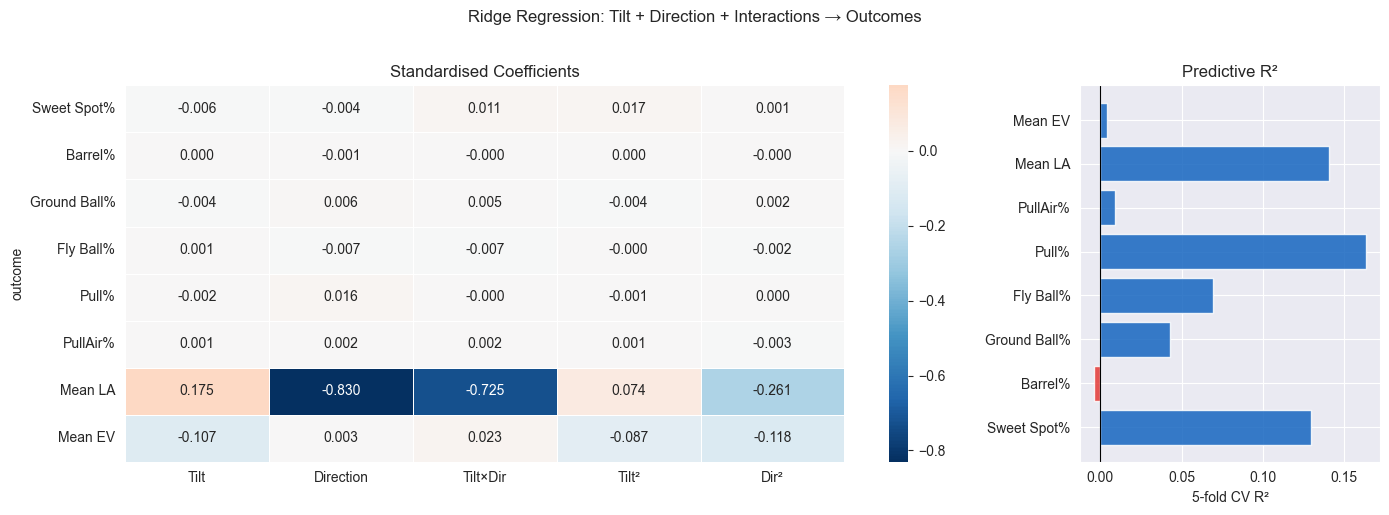

In [23]:
coef_cols = ["Tilt", "Direction", "Tilt×Dir", "Tilt²", "Dir²"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5),
                          gridspec_kw={"width_ratios": [3, 1]})

sns.heatmap(
    reg_df[coef_cols],
    annot=True, fmt=".3f",
    cmap="RdBu_r", center=0,
    linewidths=0.5, linecolor="white",
    ax=axes[0],
)
axes[0].set_title("Standardised Coefficients")

r2_vals = reg_df["cv_r2"]
colors  = ["#1565C0" if v > 0 else "#E53935" for v in r2_vals]
axes[1].barh(r2_vals.index, r2_vals.values, color=colors, alpha=0.85)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_xlabel("5-fold CV R²")
axes[1].set_title("Predictive R²")

plt.suptitle("Ridge Regression: Tilt + Direction + Interactions → Outcomes",
             y=1.02, fontsize=12)
plt.tight_layout()
plt.show()


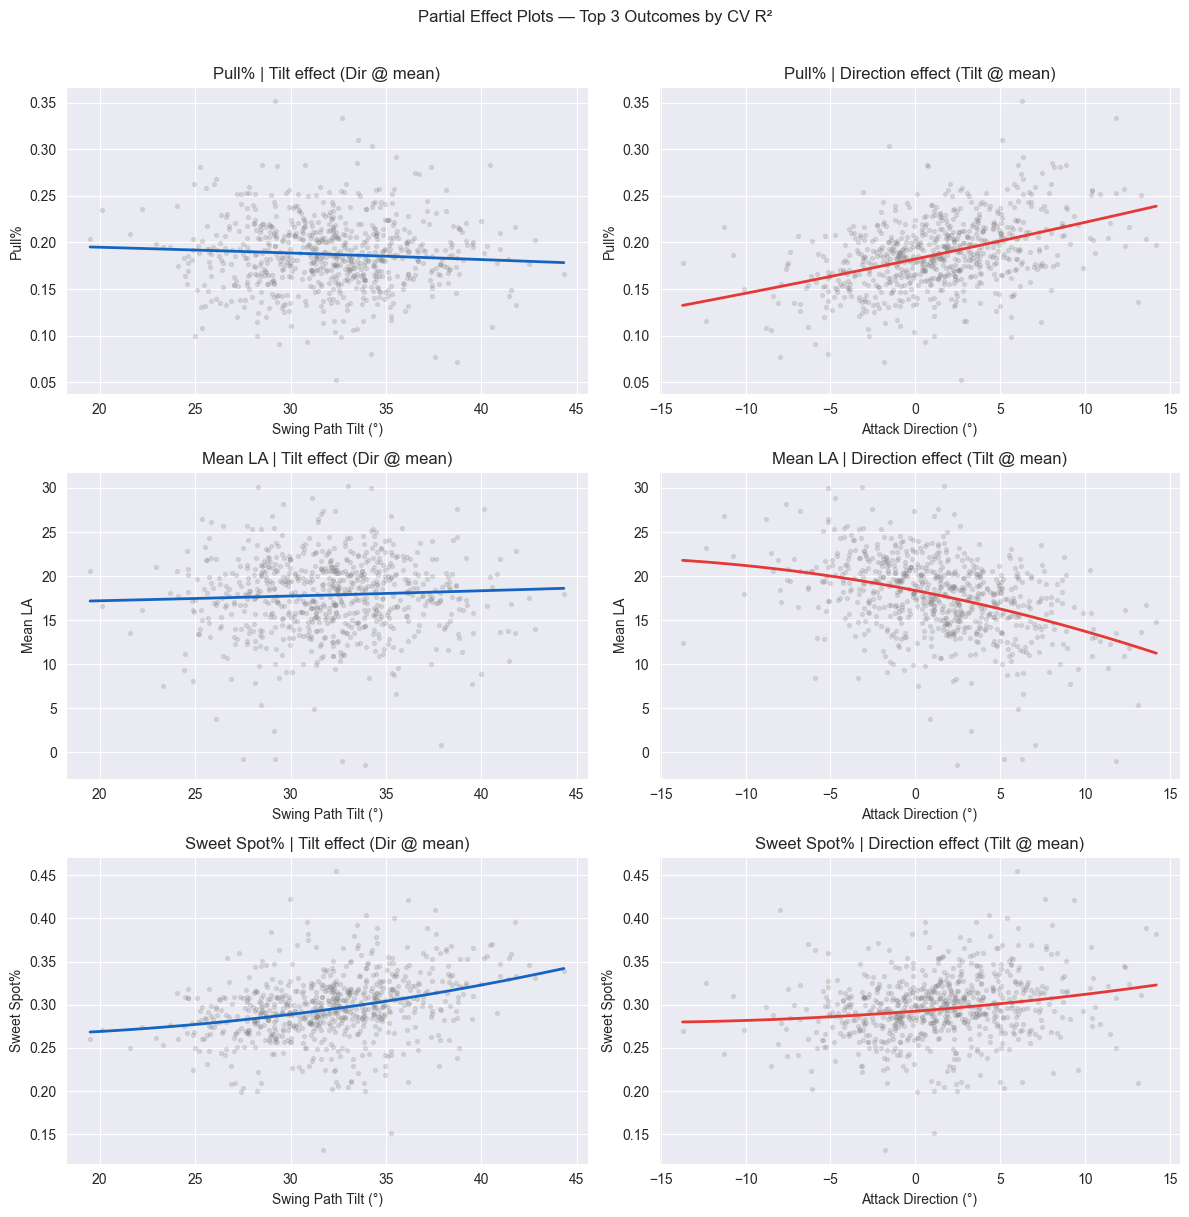

In [24]:
# ── Partial effect plots for top 3 outcomes by CV R² ─────────────────────────
top3 = reg_df["cv_r2"].nlargest(3).index.tolist()

fig, axes = plt.subplots(len(top3), 2, figsize=(12, 4 * len(top3)))

for row_idx, outcome_label in enumerate(top3):
    col = outcome_cols[outcome_label]
    sub = batter_agg[["mean_tilt", "mean_direction", col]].dropna()
    T   = sub["mean_tilt"].values
    D   = sub["mean_direction"].values
    y   = sub[col].values
    t_mean, d_mean = T.mean(), D.mean()

    X    = np.column_stack([T, D, T*D, T**2, D**2])
    pipe = Pipeline([("scaler", StandardScaler()),
                     ("ridge",  RidgeCV(alphas=[0.01, 0.1, 1, 10, 100], cv=5))])
    pipe.fit(X, y)

    tilt_grid = np.linspace(T.min(), T.max(), 100)
    dir_grid  = np.linspace(D.min(), D.max(), 100)

    # Partial: vary tilt, hold direction at mean
    X_t = np.column_stack([tilt_grid, np.full_like(tilt_grid, d_mean),
                            tilt_grid * d_mean, tilt_grid**2,
                            np.full_like(tilt_grid, d_mean**2)])
    axes[row_idx, 0].scatter(T, y, alpha=0.2, s=8, color="gray")
    axes[row_idx, 0].plot(tilt_grid, pipe.predict(X_t), color="#1565C0", linewidth=2)
    axes[row_idx, 0].set_xlabel("Swing Path Tilt (°)")
    axes[row_idx, 0].set_ylabel(outcome_label)
    axes[row_idx, 0].set_title(f"{outcome_label} | Tilt effect (Dir @ mean)")

    # Partial: vary direction, hold tilt at mean
    X_d = np.column_stack([np.full_like(dir_grid, t_mean), dir_grid,
                            t_mean * dir_grid, np.full_like(dir_grid, t_mean**2),
                            dir_grid**2])
    axes[row_idx, 1].scatter(D, y, alpha=0.2, s=8, color="gray")
    axes[row_idx, 1].plot(dir_grid, pipe.predict(X_d), color="#E53935", linewidth=2)
    axes[row_idx, 1].set_xlabel("Attack Direction (°)")
    axes[row_idx, 1].set_ylabel(outcome_label)
    axes[row_idx, 1].set_title(f"{outcome_label} | Direction effect (Tilt @ mean)")

plt.suptitle("Partial Effect Plots — Top 3 Outcomes by CV R²",
             y=1.01, fontsize=12)
plt.tight_layout()
plt.show()
